# Experiment 3: Breadth-first and depth-first search
**Aim.** To represent a maze as an implicit graph, to implement BFS and DFS as one function differing in a single line,
and to compare them on cells expanded and path length.

## Theory (summary)
* Frontier, explored set and parent map.
* **BFS** pops the *oldest* state (FIFO). Every edge costs the same, so the first path to the goal is a shortest path.
* **DFS** pops the *newest* state (LIFO). It gives no optimality guarantee and needs $O(bm)$ memory against $O(b^d)$ for BFS.

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figs', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

### Building the maze
The manual refers to a randomized-DFS carver (`make_fig3.py`). The version below carves a perfect maze of
23 × 35 cells. It then knocks out a few extra walls to create loops, so that BFS and DFS can return different paths.

In [2]:
from collections import deque

def carve_maze(H=23, W=35, extra_openings=8, seed=3):
    rng = np.random.default_rng(seed)
    maze = np.ones((H, W), dtype=int)               # 1 = wall, 0 = open
    stack = [(1, 1)]; maze[1, 1] = 0
    while stack:
        r, c = stack[-1]
        nbrs = [(r+dr, c+dc, r+dr//2, c+dc//2) for dr, dc in ((-2,0),(2,0),(0,-2),(0,2))
                if 0 < r+dr < H-1 and 0 < c+dc < W-1 and maze[r+dr, c+dc] == 1]
        if nbrs:
            nr, nc, wr, wc = nbrs[rng.integers(len(nbrs))]
            maze[wr, wc] = 0; maze[nr, nc] = 0
            stack.append((nr, nc))
        else:
            stack.pop()
    # knock out interior walls that separate two open cells -> creates loops
    cand = [(r, c) for r in range(1, H-1) for c in range(1, W-1) if maze[r, c] == 1 and
            ((maze[r-1, c] == 0 and maze[r+1, c] == 0 and maze[r, c-1] == 1 and maze[r, c+1] == 1) or
             (maze[r, c-1] == 0 and maze[r, c+1] == 0 and maze[r-1, c] == 1 and maze[r+1, c] == 1))]
    for i in rng.choice(len(cand), size=extra_openings, replace=False):
        maze[cand[i]] = 0
    return maze

maze = carve_maze()
print('maze shape:', maze.shape, ' open cells:', int((maze == 0).sum()))

maze shape: (23, 35)  open cells: 381


## Example 1: The maze as an implicit graph

In [3]:
H, W = maze.shape
START, GOAL = (1, 1), (H-2, W-2)

def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1,0), (1,0), (0,-1), (0,1)):     # up, down, left, right
        nr, nc = r+dr, c+dc
        if 0 <= nr < H and 0 <= nc < W:               # BOUNDS FIRST
            if maze[nr, nc] == 0:                     # then contents
                yield (nr, nc)

print('neighbours of START:', list(neighbours(START)))

neighbours of START: [(1, 2)]


## Example 2: One function, two algorithms

In [4]:
def search(start, goal, mode='bfs'):
    frontier = deque([start])
    parent = {start: None}          # doubles as the explored set
    order = {}                      # cell -> the step at which it was expanded
    while frontier:
        node = frontier.popleft() if mode == 'bfs' else frontier.pop()
        # <---- THE ONLY DIFFERENCE BETWEEN THE TWO ALGORITHMS
        if node in order: continue
        order[node] = len(order)
        if node == goal: break
        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)
    path, cur = [], goal
    if goal in parent:
        while cur is not None:
            path.append(cur); cur = parent[cur]
    return order, path[::-1]

def validate(path):
    ok_ends = path[0] == START and path[-1] == GOAL
    ok_adj = all(abs(a[0]-b[0]) + abs(a[1]-b[1]) == 1 for a, b in zip(path, path[1:]))
    ok_open = all(maze[r, c] == 0 for r, c in path)
    return ok_ends and ok_adj and ok_open

results = {}
for mode in ('bfs', 'dfs'):
    order, path = search(START, GOAL, mode)
    results[mode] = (order, path)
    print(f'{mode.upper()}: {len(order)} expanded, path length {len(path)}, valid = {validate(path)}')

BFS: 267 expanded, path length 69, valid = True
DFS: 121 expanded, path length 107, valid = True


## Example 3: Watching the frontier

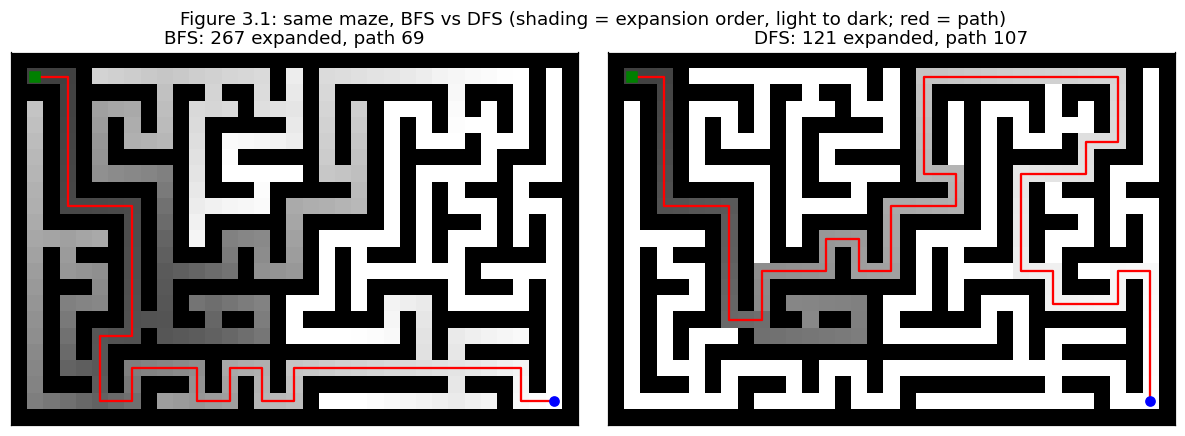

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, mode in zip(axes, ['bfs', 'dfs']):
    order, path = results[mode]
    grid = np.full(maze.shape, np.nan)              # nan = never expanded
    for (r, c), k in order.items():
        grid[r, c] = k                              # shade by expansion order
    ax.imshow(maze, cmap='binary')
    ax.imshow(grid, cmap='Greys_r', alpha=0.75)
    ax.plot([c for _, c in path], [r for r, _ in path], lw=1.5, color='r')
    ax.plot(START[1], START[0], 'gs'); ax.plot(GOAL[1], GOAL[0], 'bo')
    ax.set_title(f'{mode.upper()}: {len(order)} expanded, path {len(path)}')
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Figure 3.1: same maze, BFS vs DFS (shading = expansion order, light to dark; red = path)')
plt.tight_layout(); plt.savefig('figs/fig3_1_bfs_dfs.png'); plt.show()

### Does the result depend on where the goal is? (several goal positions)

In [6]:
open_cells = [tuple(p) for p in np.argwhere(maze == 0)]
rng = np.random.default_rng(1)
print(f"{'goal':>10} {'BFS exp':>8} {'BFS len':>8} {'DFS exp':>8} {'DFS len':>8}")
for i in rng.choice(len(open_cells), 6, replace=False):
    g_ = tuple(int(v) for v in open_cells[i])
    ob, pb = search(START, g_, 'bfs'); od, pd = search(START, g_, 'dfs')
    print(f'{str(g_):>10} {len(ob):>8} {len(pb):>8} {len(od):>8} {len(pd):>8}')

      goal  BFS exp  BFS len  DFS exp  DFS len
   (17, 6)       25       24      198      180
  (11, 22)      357       84      232      142
  (21, 10)      106       40      152      138
   (11, 1)      123       43      177      161
   (3, 25)      297       73      243      153
   (1, 15)      188       57      341       57


In [7]:
ob, pb = results['bfs']; od, pd = results['dfs']
print('Table 3.1')
print(f"{'Algorithm':<22}{'Cells expanded':>15}{'Path length':>13}  Shortest?")
print(f"{'Breadth-first search':<22}{len(ob):>15}{len(pb):>13}  yes, guaranteed")
print(f"{'Depth-first search':<22}{len(od):>15}{len(pd):>13}  {'yes (by luck)' if len(pd) == len(pb) else 'no'}")
print(f'Maze {H} x {W}, {len(open_cells)} open cells')

Table 3.1
Algorithm              Cells expanded  Path length  Shortest?
Breadth-first search              267           69  yes, guaranteed
Depth-first search                121          107  no
Maze 23 x 35, 381 open cells


## Observations to record
The maze dimensions, open-cell count, cells expanded and path lengths are in the table above.
The validation result for each path is printed by `validate()`, which checks that every step is adjacent and on an open cell.

## Discussion
* **Expected:** BFS returns a shortest path. DFS returns some path, possibly longer, and may expand more or fewer cells.
* **Observed:** see the table. The BFS path is the shortest available, guaranteed because BFS expands in order of depth.
  DFS's cost depends on where the goal lies relative to its branch ordering. The multi-goal table shows DFS sometimes
  expanding fewer cells and sometimes more.
* Neither the cell counts nor the lengths are general properties of the algorithms. Only BFS's optimality guarantee is general.

## Viva questions (short answers)
1. You can conclude the BFS path is shortest and DFS's is not. You cannot conclude that DFS is generally cheaper or more expensive.
2. A negative index wraps around in NumPy (`maze[-1, c]`), so a contents-first check silently reads the far side of the grid.
3. Marking on enqueue stops the same cell entering the frontier many times.
4. BFS needs $O(b^d)$ memory and DFS needs $O(bm)$. On a memory-constrained robot choose DFS (or iterative deepening).
5. Yes, if every move (including diagonal ones) counts as one step. If diagonal steps cost $\sqrt2$, plain BFS is no longer optimal; use Dijkstra or A*.